# Phase-of-play segmentation

**Analytical question:** Split a match into interpretable tactical states.

**Stages in this notebook:** Features; rule gates; confirmation; interval construction; provider-label joins.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Define uninterrupted possessions

Create the row keys, elapsed times and attack-normalized coordinates before deriving tactical features.

In [4]:
frame=wide[['period_id','frame_id','timestamp','ball_x','ball_y','ball_owning_team_id']].copy().sort_values(['period_id','frame_id'])
frame['seconds']=frame.timestamp.dt.total_seconds();frame['sign']=np.where(frame.ball_owning_team_id.eq(1802),-1,1);frame['attack_x']=frame.ball_x*frame.sign
new=frame.period_id.ne(frame.period_id.shift())|frame.frame_id.diff().ne(1)|frame.ball_owning_team_id.ne(frame.ball_owning_team_id.shift())
frame['possession_segment']=new.cumsum();frame['possession_age']=frame.seconds-frame.groupby('possession_segment').seconds.transform('first')
display(frame[['frame_id','attack_x','possession_segment','possession_age']].head(12))

,frame_id,attack_x,possession_segment,possession_age
0,40,-0.64,1,0.0
1,41,-1.10,1,0.1
2,42,-1.70,1,0.2
3,43,-2.36,1,0.3
4,44,-3.04,1,0.4
5,45,-3.69,1,0.5
6,46,-4.25,1,0.6
7,47,-4.76,1,0.7
8,48,-5.27,1,0.8
9,49,-5.75,1,0.9


## 5. Derive progress features

Inspect displacement, elapsed time and a historical rolling average within one possession.

,seconds,attack_x,dx,dt,instant_speed,past_mean
765,134.4,-15.80,NaN,NaN,NaN,NaN
766,134.5,-15.32,0.48,0.1,4.8,NaN
767,134.6,-14.78,0.54,0.1,5.4,NaN
768,134.7,-14.29,0.49,0.1,4.9,NaN
769,134.8,-13.80,0.49,0.1,4.9,NaN
770,134.9,-13.33,0.47,0.1,4.7,4.940000
771,135.0,-12.93,0.40,0.1,4.0,4.783333
772,135.1,-12.56,0.37,0.1,3.7,4.628571
773,135.2,-12.20,0.36,0.1,3.6,4.500000
774,135.3,-11.84,0.36,0.1,3.6,4.400000


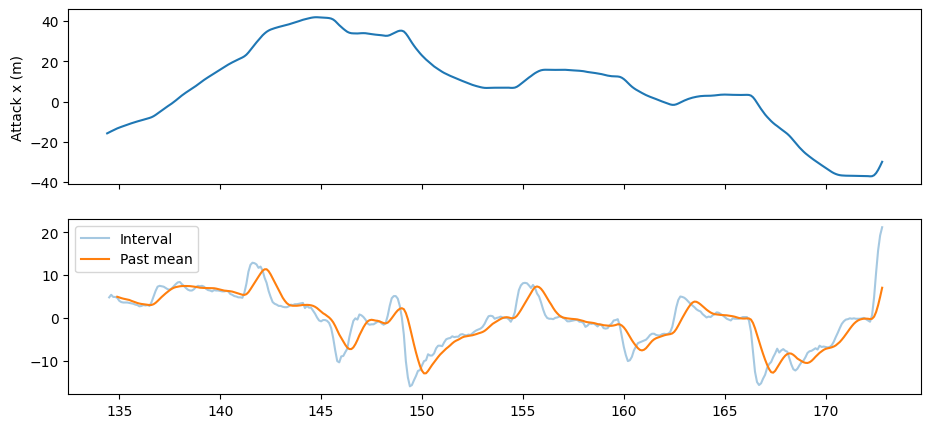

In [5]:
def progression_diagnostics(segment):
    result=segment.copy();result['dx']=result.attack_x.diff();result['dt']=result.seconds.diff()
    result['instant_speed']=result.dx/result.dt
    result['past_mean']=result.instant_speed.rolling(10,min_periods=5).mean()
    return result
segment_id=frame.groupby('possession_segment').size().idxmax();diagnostic=progression_diagnostics(frame[frame.possession_segment.eq(segment_id)])
display(diagnostic[['seconds','attack_x','dx','dt','instant_speed','past_mean']].head(12))
fig,axs=plt.subplots(2,1,figsize=(11,5),sharex=True);axs[0].plot(diagnostic.seconds,diagnostic.attack_x);axs[0].set_ylabel('Attack x (m)');axs[1].plot(diagnostic.seconds,diagnostic.instant_speed,alpha=.4,label='Interval');axs[1].plot(diagnostic.seconds,diagnostic.past_mean,label='Past mean');axs[1].legend();plt.show()
frame['progress_speed']=frame.groupby('possession_segment').attack_x.diff()/frame.groupby('possession_segment').seconds.diff()
frame['progress_1s']=frame.groupby('possession_segment').progress_speed.transform(lambda s:s.rolling(10,min_periods=5).mean())

## 6. Inspect rule gates

Make each Boolean decision visible before combining them into a state label.

,early_possession,fast_progress,deep_zone,advanced_zone
0,True,False,False,False
1,True,False,False,False
2,True,False,False,False
3,True,False,False,False
4,True,False,False,False
5,True,False,False,False
6,True,False,False,False
7,True,False,False,False
8,True,False,False,False
9,True,False,False,False


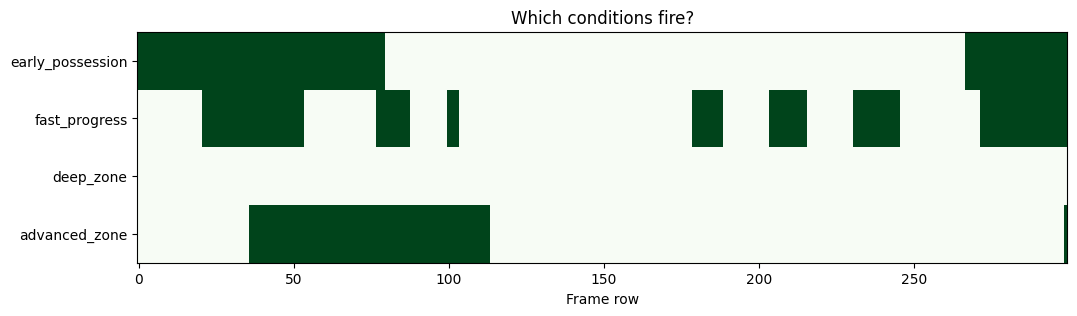

In [6]:
def phase_rule_gates(frames):
    return pd.DataFrame({'early_possession':frames.possession_age.lt(8),'fast_progress':frames.progress_1s.gt(3),'deep_zone':frames.attack_x.lt(-17.5),'advanced_zone':frames.attack_x.ge(17.5)},index=frames.index)
sample=frame.head(300);gates=phase_rule_gates(sample);display(gates.head(12))
plt.figure(figsize=(12,3));plt.imshow(gates.to_numpy().T,aspect='auto',cmap='Greens');plt.yticks(range(4),gates.columns);plt.xlabel('Frame row');plt.title('Which conditions fire?');plt.show()

## 7. Assign raw states and confirm them

Apply the state rules, then require repeated evidence before switching labels.

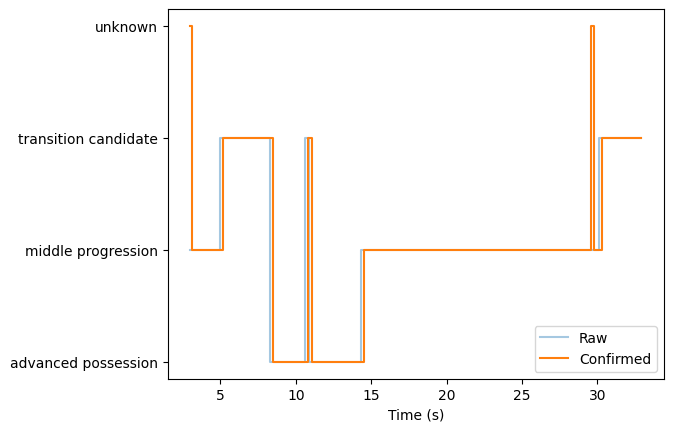

In [7]:
def rule_phase(row):
    if pd.isna(row.attack_x) or row.ball_owning_team_id not in [1802,871]:return 'unknown'
    if row.possession_age<8 and row.progress_1s>3:return 'transition candidate'
    if row.attack_x<-17.5:return 'deep circulation'
    if row.attack_x<17.5:return 'middle progression'
    return 'advanced possession'

def smooth_states(g):
    current='unknown';pending=None;n=0;output=[]
    for label in g.raw_phase:
        n=n+1 if label==pending else 1;pending=label
        if n>=3:current=label
        output.append(current)
    return pd.Series(output,index=g.index)
frame['raw_phase']=frame.apply(rule_phase,axis=1)
frame['phase']=pd.concat([smooth_states(g) for _,g in frame.groupby('possession_segment')]).sort_index()
sample=frame.head(300);labels=sorted(set(sample.raw_phase)|set(sample.phase));mapping={v:i for i,v in enumerate(labels)}
plt.step(sample.seconds,sample.raw_phase.map(mapping),label='Raw',alpha=.4);plt.step(sample.seconds,sample.phase.map(mapping),label='Confirmed');plt.yticks(range(len(labels)),labels);plt.xlabel('Time (s)');plt.legend();plt.show()

## 8. Final output: phase intervals and provider comparison

Build intervals from confirmed labels. Join supplied phase intervals using period, inclusive frame boundaries and possession team.

,period,start,end,phase,n,duration_s
1,1,3.0,3.1,unknown,2,0.2
2,1,3.2,5.2,middle progression,21,2.1
3,1,5.3,8.5,transition candidate,33,3.3
4,1,8.6,10.8,advanced possession,23,2.3
5,1,10.9,11.1,transition candidate,3,0.3
6,1,11.2,14.5,advanced possession,34,3.4
7,1,14.6,29.6,middle progression,151,15.1
8,1,29.7,29.8,unknown,2,0.2
9,1,29.9,30.3,middle progression,5,0.5
10,1,30.4,33.7,transition candidate,34,3.4


provider_matches
1    5103
0    1015
2      35
Name: count, dtype: int64

provider_phase,build_up,chaotic,create,direct,finish,quick_break,set_play,transition
phase,,,,,,,,
advanced possession,0,32,13,44,840,75,38,56
deep circulation,726,121,244,45,0,0,0,12
middle progression,1,20,1675,128,280,0,0,50
transition candidate,50,74,160,88,180,21,0,94
unknown,8,14,20,2,16,4,3,4


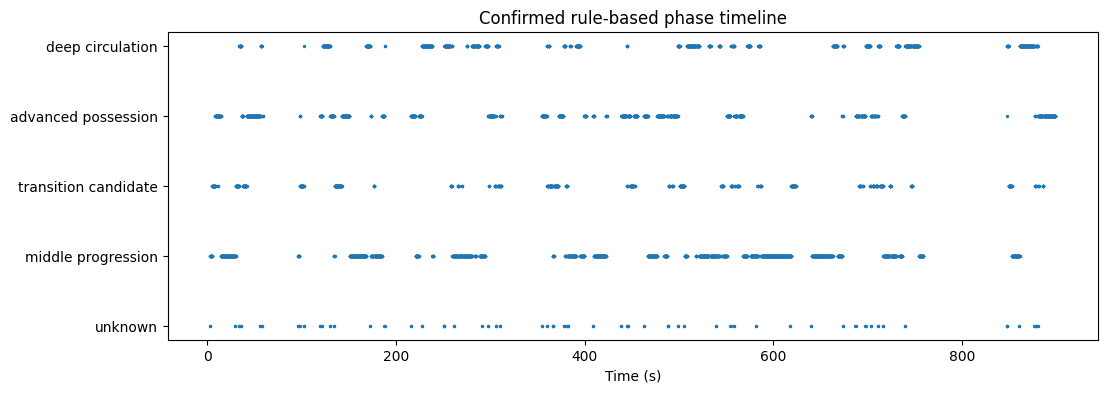

In [8]:
breaks=frame.phase.ne(frame.phase.shift())|new
intervals=frame.groupby(breaks.cumsum()).agg(period=('period_id','first'),start=('seconds','min'),end=('seconds','max'),phase=('phase','first'),n=('frame_id','size'))
intervals['duration_s']=intervals.end-intervals.start+.1;display(intervals.head(12))
frame['provider_phase']=None;frame['provider_matches']=0
for r in phases.itertuples():
    mask=frame.period_id.eq(r.period)&frame.frame_id.between(r.frame_start,r.frame_end)&frame.ball_owning_team_id.eq(r.team_in_possession_id)
    frame.loc[mask,'provider_matches']+=1;frame.loc[mask,'provider_phase']=r.team_in_possession_phase_type
display(frame.provider_matches.value_counts());display(pd.crosstab(frame.phase,frame.provider_phase))
mapping={v:i for i,v in enumerate(frame.phase.unique())};plt.figure(figsize=(12,4));plt.scatter(frame.seconds,frame.phase.map(mapping),s=2);plt.yticks(list(mapping.values()),list(mapping));plt.xlabel('Time (s)');plt.title('Confirmed rule-based phase timeline');plt.show()

### Video: estimated versus supplied phases

Compare the rule-based estimate with supplied SkillCorner phases on a real transition clip. The taxonomies differ: mismatches are not automatically classification errors, and no unreviewed accuracy score is claimed. Both timelines share the same frame/time alignment.

This MP4 is embedded in the saved notebook and HTML. It plays without a live kernel; the cell reloads the local asset or a checksum-verified pinned public copy.

In [ ]:
# Optional MP4 playback; method calculations remain inline above.
from pathlib import Path
import hashlib
import urllib.request
from IPython.display import Video, display

video_name = "phase_comparison.mp4"
video_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "assets" / "videos" / video_name).is_file()), None)
if video_root is not None:
    video_bytes = (video_root / "assets" / "videos" / video_name).read_bytes()
else:
    video_cache = Path.cwd() / "data" / "workshop_videos"
    video_cache.mkdir(parents=True, exist_ok=True)
    video_file = video_cache / video_name
    if not video_file.exists():
        video_url = ("https://raw.githubusercontent.com/zcochran27/"
                     "tracking-data-applied-workshop/62abf20cbf699df0118c289b91246a166f7bfd85/assets/videos/" + video_name)
        with urllib.request.urlopen(video_url, timeout=90) as response:
            video_file.write_bytes(response.read())
    video_bytes = video_file.read_bytes()
assert hashlib.sha256(video_bytes).hexdigest() == "3c9ed581f5928eacb26d93f466ba26c23bcc9198dc3fa33e3dc0e4b7dbe139ee", "Video checksum mismatch"
display(Video(data=video_bytes, embed=True, mimetype="video/mp4", width=960,
              html_attributes='controls preload="metadata" style="max-width:100%;height:auto"'))


## Interpretation and limitations

These rules and thresholds are teaching choices, not SkillCorner phase definitions. A cross-tabulation of different taxonomies is not an accuracy score. Match-level splits and reviewed phase boundaries are needed for evaluation.